# Lab03 — Phần 2: Phân đoạn ảnh bằng K-Means 

Notebook đi từng bước từ ảnh RGB đến các cụm màu và ảnh phân đoạn. Dùng class `KMeansScratch` của dự án, kế thừa lõi NumPy tự viết trong `Lab03/algorithms/kmeans.py`; các cell dưới không gọi K-Means của sklearn.

Bài tham khảo khởi tạo tâm ngẫu nhiên và thực hiện học ngay trong `predict`. Dự án dùng k-means++, nhiều lần khởi tạo, ngưỡng `tol`; `fit` học tâm, `predict` gán dữ liệu vào tâm đã học. Đây là triển khai của dự án theo nguyên lý trong tài liệu, không chép nguyên mã bài viết.

## 1. Chuẩn bị
Mỗi pixel là một mẫu có ba đặc trưng R, G, B. Đây là học không giám sát: không có nhãn đáp án của vật thể. Hai ảnh minh họa là tranh bãi biển và ảnh hoa.

In [2]:
from pathlib import Path
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Lab03/config.yaml").is_file())
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
from Lab03.src.part2_image.kmeans_scratch import KMeansScratch
from Lab03.src.part2_image.preprocessing import prepare_image, reconstruct_image
from Lab03.src.part2_image.segment import segment_full_resolution
image_paths = [repo / "Lab03/data/images/raw" / name for name in ("draw_beach.jpg", "photo_flower.jpg")]
settings = dict(k_values=[2, 4, 8, 16], max_size=192, max_iter=100, tol=1e-4, random_state=42, n_init=3)
print("Class dùng để học:", KMeansScratch.__module__)
print(settings)

Class dùng để học: Lab03.src.part2_image.kmeans_scratch
{'k_values': [2, 4, 8, 16], 'max_size': 192, 'max_iter': 100, 'tol': 0.0001, 'random_state': 42, 'n_init': 3}


## 2. Đọc ảnh, thu nhỏ và chuyển thành ma trận pixel
PIL đọc ảnh và chuyển RGB; không cần đổi BGR → RGB như khi đọc bằng OpenCV trong tài liệu. Giữ tỷ lệ ảnh, cạnh dài tối đa 192 pixel để thực nghiệm nhanh.

Ảnh `(H, W, 3)` được trải thành `(H × W, 3)`, chuyển số thực và chia 255. Chuẩn hóa chung ba kênh chỉ thay thang khoảng cách, không làm đổi tâm gần nhất khi các tâm được đổi cùng thang.

draw_beach.jpg gốc: (1600, 1246) thu nhỏ: (150, 192, 3) X: (28800, 3)
photo_flower.jpg gốc: (3840, 2160) thu nhỏ: (108, 192, 3) X: (20736, 3)


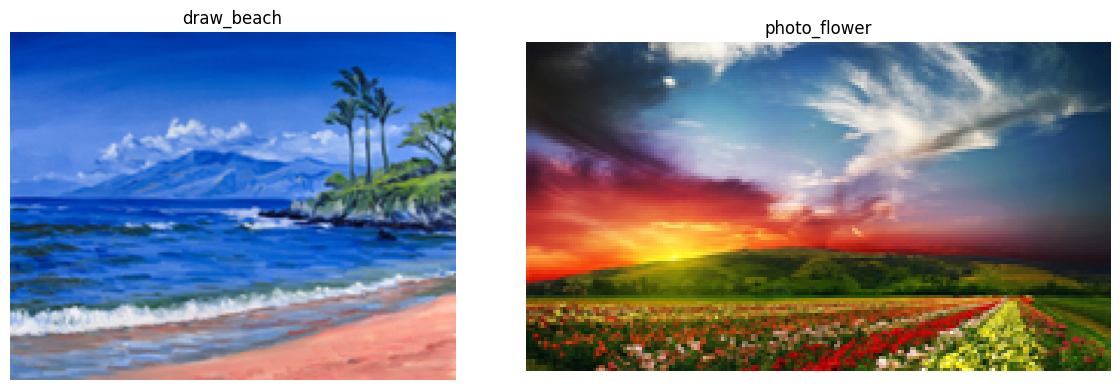

5 pixel RGB chuẩn hóa đầu tiên: [[0.00392157 0.18823529 0.56078431]
 [0.00392157 0.15686275 0.58039216]
 [0.00784314 0.16862745 0.59607843]
 [0.00392157 0.17647059 0.59607843]
 [0.00784314 0.17254902 0.59215686]]


In [3]:
prepared = {}
fig, axes = plt.subplots(1, len(image_paths), figsize=(12, 4))
for ax, path in zip(axes, image_paths):
    X, resized, original = prepare_image(path, settings["max_size"], colorspace="RGB")
    prepared[path.stem] = (X, resized, original)
    print(path.name, "gốc:", original.size, "thu nhỏ:", resized.shape, "X:", X.shape)
    ax.imshow(resized)
    ax.set_title(path.stem)
    ax.axis("off")
plt.tight_layout()
plt.show()
X, resized, original = prepared[image_paths[0].stem]
print("5 pixel RGB chuẩn hóa đầu tiên:", X[:5])

## 3. K-Means học như thế nào?
1. Khởi tạo K tâm bằng k-means++.
2. Tính khoảng cách từ mỗi pixel đến các tâm; gán vào tâm gần nhất.
3. Cập nhật mỗi tâm bằng trung bình vector màu của cụm.
4. Lặp đến khi tâm dịch chuyển không quá `tol` hoặc đạt `max_iter`.
5. Thử `n_init` lần và giữ nghiệm có inertia nhỏ nhất.

Cụm rỗng được xử lý trong lõi thuật toán. Bình phương khoảng cách Euclid được dùng để tìm tâm gần nhất; bỏ căn không đổi thứ tự khoảng cách.

Cell sau minh họa phép gán và cập nhật bằng **tâm của một mô hình đã fit**, không phải lịch sử từng vòng huấn luyện.

In [4]:
model = KMeansScratch(n_clusters=4, max_iter=settings["max_iter"], tol=settings["tol"],
                      random_state=settings["random_state"], n_init=settings["n_init"]).fit(X)
centers = model.centroids_
distance_squared = ((X[:5, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
print("Khoảng cách bình phương của 5 pixel tới 4 tâm:", distance_squared)
print("Nhãn cụm gần nhất:", distance_squared.argmin(axis=1))
labels = model.predict(X)
cluster_zero = X[labels == 0]
print("Trung bình màu cụm 0:", cluster_zero.mean(axis=0))
print("Tâm cụm 0 đã học:", centers[0])
print("Số vòng:", model.n_iter_, "Hội tụ:", model.converged_, "Inertia:", model.inertia_)

Khoảng cách bình phương của 5 pixel tới 4 tâm: [[0.32803122 0.05740604 0.85841592 0.12013267]
 [0.34127105 0.06094893 0.88532935 0.13841433]
 [0.32204859 0.05165665 0.86622589 0.13763208]
 [0.3190766  0.04950845 0.86513828 0.13670937]
 [0.3209433  0.05151646 0.86285616 0.13465232]]
Nhãn cụm gần nhất: [1 1 1 1 1]
Trung bình màu cụm 0: [0.36755516 0.54285012 0.8254542 ]
Tâm cụm 0 đã học: [0.36755516 0.54285012 0.8254542 ]
Số vòng: 17 Hội tụ: True Inertia: 869.4310505651129


## 4. Thay pixel bằng màu tâm và ghép lại ảnh
`centers[labels]` tạo một màu đại diện cho từng pixel. Đổi về RGB 0–255 rồi reshape về `(H, W, 3)`. Nhãn 0, 1, 2… chỉ là số cụm, không có nghĩa cố định như biển hay cây.

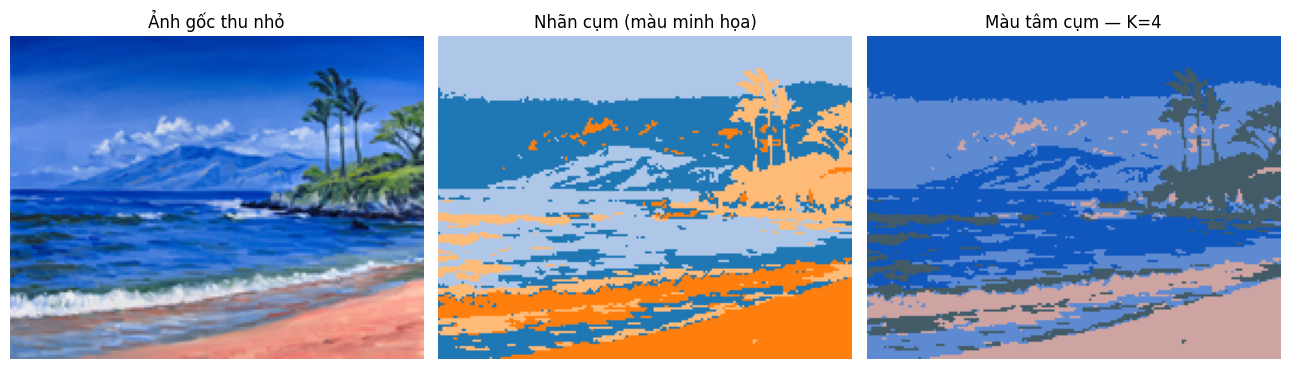

In [7]:
segmented = reconstruct_image(centers[labels], resized.shape, "RGB")
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(resized); axes[0].set_title("Ảnh gốc thu nhỏ")
axes[1].imshow(labels.reshape(resized.shape[:2]), cmap="tab20", vmin=0, vmax=19)
axes[1].set_title("Nhãn cụm (màu minh họa)")
axes[2].imshow(segmented); axes[2].set_title("Màu tâm cụm — K=4")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Minh họa che một cụm 
Đặt pixel thuộc một cụm thành màu đen để thấy vùng ảnh cụm đó đại diện. Cụm màu có thể nằm ở nhiều vị trí và nhiều vật thể khác nhau.

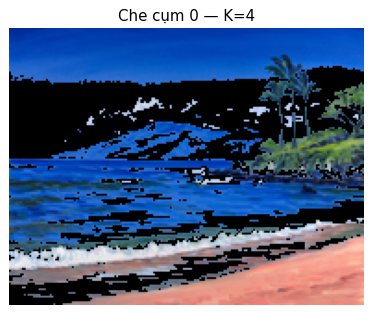

In [5]:
cluster_to_hide = 0  # đổi thành 0, 1, 2 hoặc 3
masked = resized.copy().reshape(-1, 3)
masked[labels == cluster_to_hide] = [0, 0, 0]
plt.figure(figsize=(6, 4))
plt.imshow(masked.reshape(resized.shape))
plt.title(f"Che cụm {cluster_to_hide} — K=4")
plt.axis("off"); plt.show()

## 6. Thực nghiệm K = 2, 4, 8, 16 trên cả hai ảnh
Mỗi cấu hình học độc lập. Inertia là tổng bình phương khoảng cách tới tâm trong RGB chuẩn hóa. RMSE màu đo chênh lệch các kênh RGB giữa ảnh thu nhỏ và ảnh tái tạo. Chỉ so inertia giữa các K trên cùng ảnh, cùng kích thước và cách chuẩn hóa.

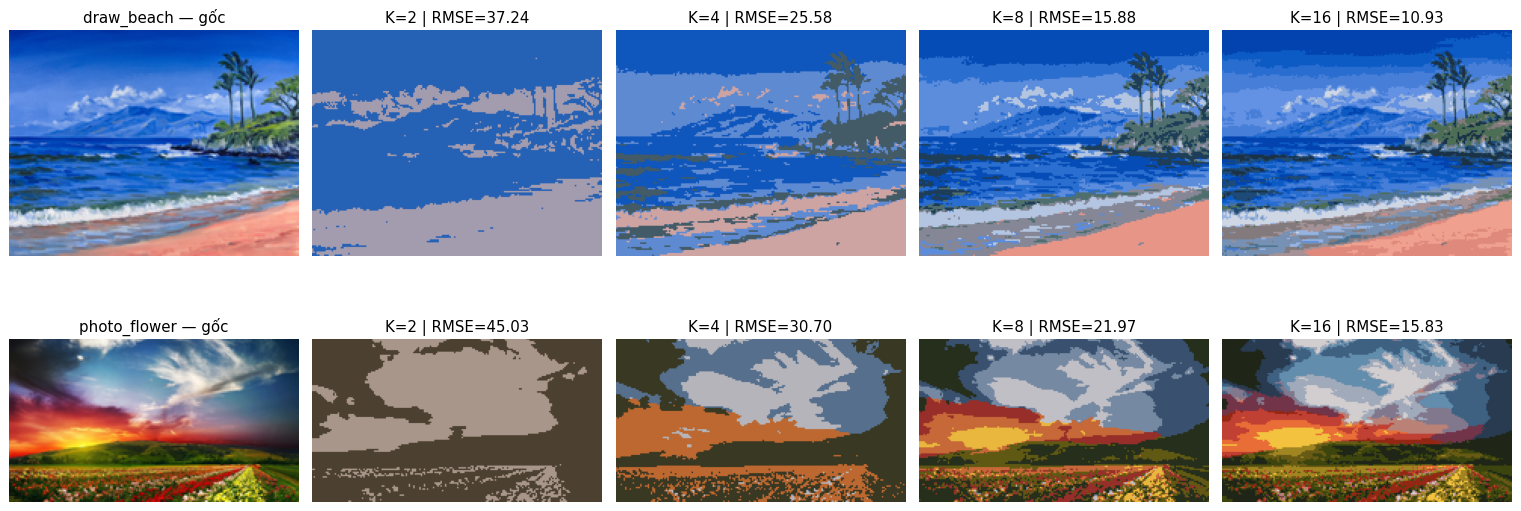

       image  k  inertia  rgb_rmse  n_iter  converged  fit_reconstruct_seconds
  draw_beach  2 1842.684    37.241      35       True                    0.231
  draw_beach  4  869.431    25.582      17       True                    0.306
  draw_beach  8  334.894    15.878      65       True                    4.151
  draw_beach 16  158.698    10.933      52       True                    7.913
photo_flower  2 1940.177    45.035      20       True                    0.306
photo_flower  4  901.340    30.696      23       True                    0.716
photo_flower  8  461.694    21.970      34       True                    2.698
photo_flower 16  239.736    15.832      41       True                    5.103


In [6]:
models, rows = {}, []
fig, axes = plt.subplots(len(prepared), len(settings["k_values"]) + 1, figsize=(17, 7))
for row_index, (name, (features, array, source)) in enumerate(prepared.items()):
    axes[row_index, 0].imshow(array)
    axes[row_index, 0].set_title(f"{name} — gốc")
    for col, k in enumerate(settings["k_values"], start=1):
        started = time.perf_counter()
        fitted = KMeansScratch(n_clusters=k, max_iter=settings["max_iter"], tol=settings["tol"],
                              random_state=settings["random_state"], n_init=settings["n_init"]).fit(features)
        output = reconstruct_image(fitted.centroids_[fitted.labels_], array.shape, "RGB")
        elapsed = time.perf_counter() - started
        rmse = float(np.sqrt(np.mean((array.astype(float) - output.astype(float)) ** 2)))
        models[name, k] = fitted
        rows.append(dict(image=name, k=k, inertia=fitted.inertia_, rgb_rmse=rmse,
                         n_iter=fitted.n_iter_, converged=fitted.converged_, fit_reconstruct_seconds=elapsed))
        axes[row_index, col].imshow(output)
        axes[row_index, col].set_title(f"K={k} | RMSE={rmse:.2f}")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()
metrics = pd.DataFrame(rows)
print(metrics.round(3).to_string(index=False))

## 7. Đọc biểu đồ đánh giá
K nhỏ tạo ít màu và làm mất chi tiết. K lớn thường giảm sai số tái tạo, nhưng tăng số màu và chi phí tính toán. Inertia giảm không chứng minh ảnh đã được tách đúng vật thể; không chọn K chỉ vì giá trị inertia thấp nhất.

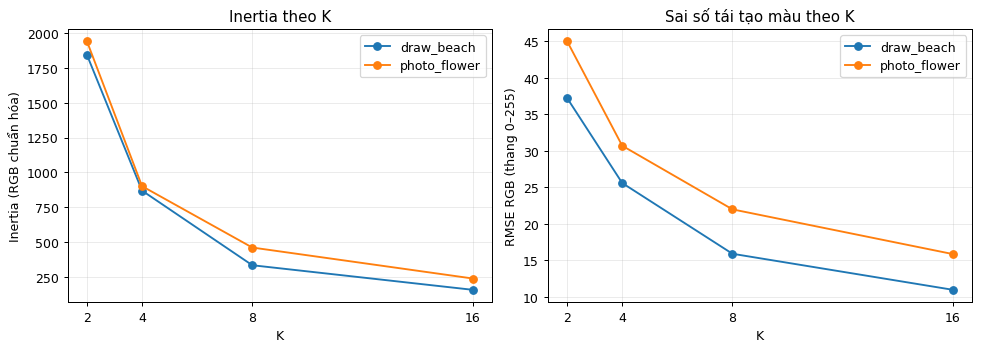

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, group in metrics.groupby("image", sort=False):
    axes[0].plot(group.k, group.inertia, "o-", label=name)
    axes[1].plot(group.k, group.rgb_rmse, "o-", label=name)
for ax, title, ylabel in zip(axes, ["Inertia theo K", "Sai số tái tạo màu theo K"], ["Inertia (RGB chuẩn hóa)", "RMSE RGB (thang 0–255)"]):
    ax.set_title(title); ax.set_xlabel("K"); ax.set_ylabel(ylabel)
    ax.set_xticks(settings["k_values"]); ax.legend(); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

## 8. Áp dụng tâm đã học lên ảnh đúng kích thước gốc
Không fit lại. Dùng `predict` gán pixel ảnh gốc vào các tâm học từ ảnh thu nhỏ. Xử lý từng lô để tránh tạo ma trận khoảng cách quá lớn. Thư mục riêng `notebook_exports` lưu ảnh K=8, bảng chỉ số và cấu hình của notebook.

In [8]:
export_dir = repo / "Lab03/notebooks/notebook_exports/part2_image"
export_dir.mkdir(parents=True, exist_ok=True)
for name, (_, _, source) in prepared.items():
    full = segment_full_resolution(source, models[name, 8], colorspace="RGB")
    assert full.shape[:2] == (source.height, source.width)
    destination = export_dir / f"{name}_k8.png"
    Image.fromarray(full).save(destination)
    print(destination, "kích thước:", (full.shape[1], full.shape[0]))
metrics.to_csv(export_dir / "metrics.csv", index=False)
(export_dir / "config_used.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")

E:\ML_Nhóm6\Lab03\notebooks\notebook_exports\part2_image\draw_beach_k8.png kích thước: (1600, 1246)
E:\ML_Nhóm6\Lab03\notebooks\notebook_exports\part2_image\photo_flower_k8.png kích thước: (3840, 2160)


## Nhận xét và câu hỏi thuyết trình
- So sánh K=2 và K=16: vùng nào mất chi tiết, vùng nào được giữ lại?
- Tâm cụm là màu trung bình; cùng một cụm có thể chứa pixel của nhiều vật thể.
- Đây là phân cụm màu không giám sát, không phải phân loại vật thể.
- `fit` học tâm, `predict` sử dụng tâm đã học, `centers[labels]` tái tạo màu.
- Notebook tập trung bản tự cài. Pipeline cũng chỉ sử dụng K-Means tự cài.

Đọc thêm: [báo cáo Part 2](../docs/Image_Segmentation_Report.md).